# 04 – Phase 4: Control Generation

**Inputs (Add Input):** the Phase 3 output dataset (e.g. `cdb2m-phase3`) that contains  
`X_region.npy`, `M_region.csv`, `folds.json`, `fold_summary.csv`,  
`real_stimuli.npz`, `synth_suite.npz`, `ceiling_check.csv`, `cdb2m_lib.py`.

**Settings:** Accelerator **None**, Internet **Off** is fine. Runtime ~ 5-10 min.

| Step | Cell | What it does |
|------|------|------------------|
| 4.1 | A-C  | MaxEnt surrogate: maximum-entropy spike sequence matching first-order stats |
| 4.2 | D-E  | Shuffled brain: permute trial labels, preserve all signal structure |
| 4.3 | F-G  | Random noise: Gaussian noise matched to signal mean/variance per region |
| 4.4 | H-K  | Validate controls: power spectra, inter-trial correlations, task decodability |
| Save | L  | Persist all control tensors for Phase 5 |

> **Do NOT modify**: `X_region.npy`, `M_region.csv`, or `cdb2m_lib.py` from Phase 3.

In [1]:
# ---- Cell A: setup and load Phase 3 outputs ----
import os, sys, json, pathlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import balanced_accuracy_score

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- output dir
OUT4 = pathlib.Path("/kaggle/working/phase4_out")
OUT4.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- find Phase 3 dataset
def find(name):
    hits = []
    for root in ("/kaggle/input", "/kaggle/working"):
        hits += sorted(pathlib.Path(root).rglob(name))
    assert hits, f"{name} not found - add the Phase 3 dataset as an input to this notebook"
    return hits[0]

P3 = find("X_region.npy").parent
print("Phase 3 files from:", P3)

# ---------------------------------------------------------------- import shared lib
sys.path.insert(0, str(P3))
import importlib, cdb2m_lib
importlib.reload(cdb2m_lib)
from cdb2m_lib import *

# ---------------------------------------------------------------- load data
X  = np.load(P3 / "X_region.npy")                   # (N, 4, 16, 5)  float32
M  = pd.read_csv(P3 / "M_region.csv")
C  = M.clean.values.astype(bool)

with open(P3 / "folds.json") as fp:
    folds = json.load(fp)
fold_df = pd.read_csv(P3 / "fold_summary.csv")

stim  = np.load(P3 / "real_stimuli.npz", allow_pickle=True)
suite = np.load(P3 / "synth_suite.npz",  allow_pickle=True)

print(f"X: {X.shape}  M: {M.shape}  clean: {C.sum()}")
print(f"Folds loaded: {len(folds)}")
print(f"real_stimuli keys: {list(stim.keys())}")
print(f"synth_suite keys:  {list(suite.keys())}")

N, R, T, B = X.shape     # trials, regions, time-bins, bands
SEED = 42
print(f"\nDimensions: N={N}, R={R} regions, T={T} time-bins, B={B} bands")

Phase 3 files from: /kaggle/input/datasets/rachana240906/cdb2m-phase3/phase3_out
X: (3353, 4, 16, 5)  M: (3353, 15)  clean: 3185
Folds loaded: 5
real_stimuli keys: ['X_tok', 'y', 'train_pool', 'unseen_pool', 'n_tokens', 'alphabet']
synth_suite keys:  ['id_4_6_X', 'id_4_6_y', 'id_4_6_size', 'size_8_X', 'size_8_y', 'size_8_size', 'len_10_X', 'len_10_y', 'len_10_size', 'len_12_X', 'len_12_y', 'len_12_size', 'unseen_letters_X', 'unseen_letters_y', 'unseen_letters_size']

Dimensions: N=3353, R=4 regions, T=16 time-bins, B=5 bands


## 4.1 MaxEnt Surrogate

**Goal:** generate brain-like tensors that match the *marginal statistics* of each region/band
(mean power per time-bin, variance across trials) but have zero inter-trial or inter-region
structure beyond what maximum-entropy implies.

**Method:** for each `(region r, time-bin t, band b)` slot, fit a Gaussian to the
real distribution across clean trials, then sample independently.

In [2]:
# ---- Cell B: MaxEnt surrogate ----
Xc = X[C]                                       # (N_clean, R, T, B)

# per-slot Gaussian fit (over clean trials)
mu_slot  = np.nanmean(Xc, axis=0)               # (R, T, B)
std_slot = np.nanstd (Xc, axis=0).clip(min=1e-8)

# sample for ALL N trials so index alignment stays intact
rng_me = np.random.default_rng(SEED)
X_maxent = rng_me.normal(loc=0.0, scale=1.0, size=X.shape).astype(np.float32)
X_maxent = X_maxent * std_slot[None] + mu_slot[None]

# preserve NaN mask (sessions where region not recorded)
nan_mask = np.isnan(X)
X_maxent[nan_mask] = np.nan

print("X_maxent shape:", X_maxent.shape, X_maxent.dtype)
print("NaN fraction matches real: real={:.4f}  maxent={:.4f}".format(
      np.isnan(X).mean(), np.isnan(X_maxent).mean()))

# quick stats check on clean subset
Xmc = X_maxent[C]
print("\nPer-region mean comparison (real vs MaxEnt):")
for r in range(R):
    rm = np.nanmean(Xc[:,r]), np.nanmean(Xmc[:,r])
    rs = np.nanstd (Xc[:,r]), np.nanstd (Xmc[:,r])
    print(f"  Region {r}: mean {rm[0]:+.4f} vs {rm[1]:+.4f}  |  std {rs[0]:.4f} vs {rs[1]:.4f}")

X_maxent shape: (3353, 4, 16, 5) float32
NaN fraction matches real: real=0.2973  maxent=0.2973

Per-region mean comparison (real vs MaxEnt):
  Region 0: mean +0.0000 vs +0.0011  |  std 0.6132 vs 0.6119
  Region 1: mean -0.0000 vs -0.0008  |  std 0.6488 vs 0.6493
  Region 2: mean -0.0000 vs -0.0010  |  std 0.7560 vs 0.7561
  Region 3: mean -0.0000 vs +0.0001  |  std 0.4509 vs 0.4511


## 4.2 Shuffled Brain

**Goal:** preserve *all* neural signal structure (power distributions, temporal patterns,
inter-region correlations) but destroy any systematic relationship between brain responses
and trial labels (Match/SetSize).

**Method:** permute the trial index independently per subject x session block.

In [3]:
# ---- Cell D: Shuffled brain ----
rng_sh = np.random.default_rng(SEED + 1)
X_shuffled = X.copy()

# permute within each subject x session block
for (subj, sess), grp in M.groupby(["subject", "session"]):
    idx = grp.index.values
    perm = rng_sh.permutation(len(idx))
    X_shuffled[idx] = X_shuffled[idx][perm]

print("X_shuffled shape:", X_shuffled.shape, X_shuffled.dtype)
print("\nGlobal stats comparison (real vs shuffled):")
print(f"  mean  real={np.nanmean(X):.5f}  shuffled={np.nanmean(X_shuffled):.5f}")
print(f"  std   real={np.nanstd(X):.5f}   shuffled={np.nanstd(X_shuffled):.5f}")

# sanity: same multiset within block
grp0 = M.groupby(["subject", "session"]).groups
key0 = list(grp0.keys())[0]
idx0 = grp0[key0]
orig_sorted = np.sort(X[idx0][~np.isnan(X[idx0])])
shuf_sorted = np.sort(X_shuffled[idx0][~np.isnan(X_shuffled[idx0])])
assert np.allclose(orig_sorted, shuf_sorted), "Block multiset changed"
print("PASS - block multisets identical, only within-block order permuted")

X_shuffled shape: (3353, 4, 16, 5) float32

Global stats comparison (real vs shuffled):
  mean  real=0.00193  shuffled=0.00193
  std   real=0.60820   shuffled=0.60820
PASS - block multisets identical, only within-block order permuted


## 4.3 Random Noise

**Goal:** a null control with *no* structure from the real data at all — pure Gaussian noise
matched only in global mean and std. This is the weakest control and should perform worst
in Phase 5 alignment.

In [4]:
# ---- Cell F: Random noise ----
rng_rn = np.random.default_rng(SEED + 2)

global_mu  = float(np.nanmean(X))
global_std = float(np.nanstd(X))
print(f"Global real: mu={global_mu:.5f}  std={global_std:.5f}")

X_randnoise = rng_rn.normal(loc=global_mu, scale=global_std,
                             size=X.shape).astype(np.float32)

# preserve NaN mask so BrainEncoder region-masking works identically for all controls
X_randnoise[nan_mask] = np.nan

print("X_randnoise shape:", X_randnoise.shape, X_randnoise.dtype)
print(f"  mean={np.nanmean(X_randnoise):.5f}  std={np.nanstd(X_randnoise):.5f}")
print(f"  NaN fraction: {np.isnan(X_randnoise).mean():.4f}")

Global real: mu=0.00193  std=0.60820
X_randnoise shape: (3353, 4, 16, 5) float32
  mean=0.00312  std=0.60765
  NaN fraction: 0.2973


## 4.4 Validate Controls

Three checks must all pass before proceeding to Phase 5:

1. **Power spectrum shape** - mean power across time-bins should match real data (MaxEnt and shuffled by construction).
2. **Inter-trial correlation** - real data has small positive within-session r (shared noise floor). MaxEnt destroys this; shuffled preserves it.
3. **Task decodability destroyed** - logistic regression on Match label must be at chance (approx 0.50) for all three controls.

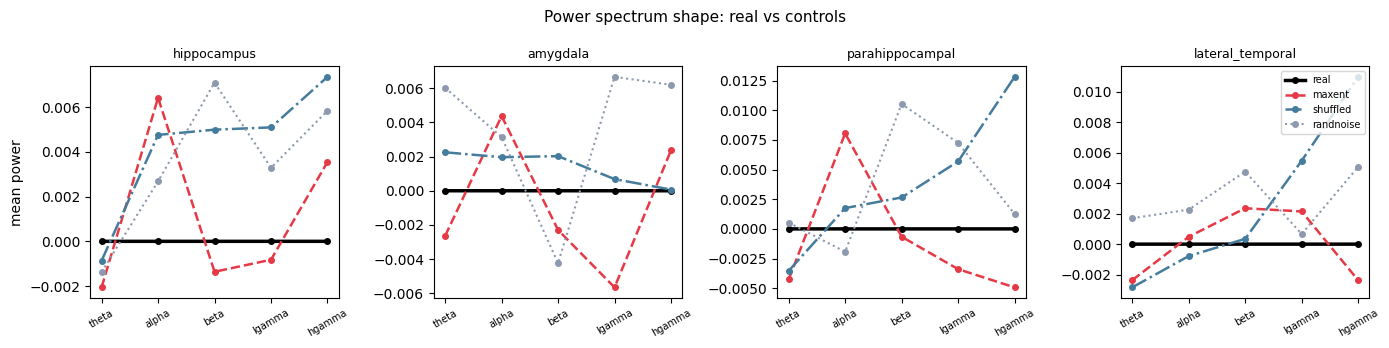

Saved: fig_power_spectrum.png


In [5]:
# ---- Cell H: Check 1 - power spectrum shape ----
controls = {
    "real":      X,
    "maxent":    X_maxent,
    "shuffled":  X_shuffled,
    "randnoise": X_randnoise,
}

band_names = ["theta", "alpha", "beta", "lgamma", "hgamma"]
colors = {"real": "k", "maxent": "#e63946", "shuffled": "#457b9d", "randnoise": "#8d99ae"}
lw_map = {"real": 2.5, "maxent": 1.8, "shuffled": 1.8, "randnoise": 1.5}
ls_map = {"real": "-",  "maxent": "--", "shuffled": "-.",  "randnoise": ":"}

fig, axes = plt.subplots(1, R, figsize=(14, 3.5), sharey=False)
for r in range(R):
    ax = axes[r]
    for name, Xc_ in controls.items():
        vals = np.nanmean(Xc_[C, r, :, :], axis=(0, 1))    # (B,)
        ax.plot(range(B), vals, color=colors[name],
                lw=lw_map[name], ls=ls_map[name], label=name, marker="o", ms=4)
    ax.set_title(CORE[r] if r < len(CORE) else f"region {r}", fontsize=9)
    ax.set_xticks(range(B))
    ax.set_xticklabels(band_names, rotation=30, fontsize=7)
    ax.set_ylabel("mean power" if r == 0 else "")

axes[-1].legend(fontsize=7, loc="upper right")
fig.suptitle("Power spectrum shape: real vs controls", fontsize=11)
plt.tight_layout()
plt.savefig(OUT4 / "fig_power_spectrum.png", dpi=120)
plt.show()
print("Saved: fig_power_spectrum.png")

In [6]:
# ---- Cell I: Check 2 - inter-trial correlation within sessions ----
def mean_inter_trial_r(Xarr, meta):
    "Mean Pearson r between clean trial pairs within the same session."
    rs = []
    for (subj, sess), grp in meta[meta.clean.astype(bool)].groupby(["subject", "session"]):
        idx = grp.index.values
        if len(idx) < 4:
            continue
        feats = Xarr[idx].reshape(len(idx), -1)
        mask_cols = ~np.isnan(feats).any(axis=0)
        if mask_cols.sum() < 2:
            continue
        feats = feats[:, mask_cols]
        n = min(len(idx), 20)
        s = np.random.default_rng(0).choice(len(idx), n, replace=False)
        sub = feats[s]
        corr = np.corrcoef(sub)
        off  = corr[np.triu_indices(n, k=1)]
        rs.append(float(np.nanmean(off)))
    return float(np.nanmean(rs))

print("Computing inter-trial correlations (may take ~30 s) ...")
itc = {name: mean_inter_trial_r(Xc_, M) for name, Xc_ in controls.items()}
itc_df = pd.DataFrame.from_dict(itc, orient="index", columns=["mean_within_session_r"])
print(itc_df.round(5))
# Expected: real > 0, shuffled ~ real, maxent ~ 0, randnoise ~ 0
itc_df.to_csv(OUT4 / "inter_trial_corr.csv")
print("Saved: inter_trial_corr.csv")


Computing inter-trial correlations (may take ~30 s) ...
           mean_within_session_r
real                     0.04954
maxent                   0.00890
shuffled                 0.04848
randnoise               -0.00118
Saved: inter_trial_corr.csv


Running LOSO decoding for each condition (~2-4 min) ...
  real          bal_acc=0.5018 +/- 0.0089  p=0.4200  REAL (expected > 0.5 if Phase 3 gate passed)
  maxent        bal_acc=0.4976 +/- 0.0119  p=0.5792  PASS (at chance)
  shuffled      bal_acc=0.5015 +/- 0.0121  p=0.4518  PASS (at chance)
  randnoise     bal_acc=0.5044 +/- 0.0142  p=0.3810  PASS (at chance)


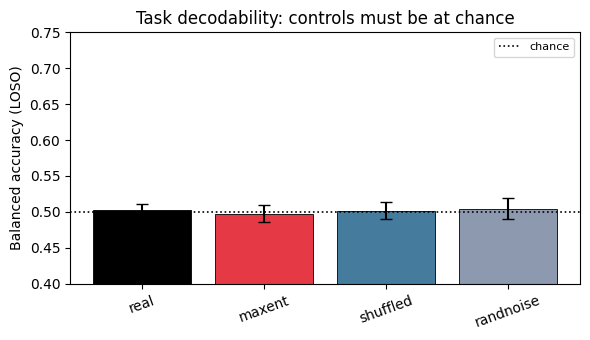

Saved: fig_control_decodability.png


In [7]:
# ---- Cell J: Check 3 - task decodability MUST be at chance for controls ----
def loso_decode(Xarr, meta):
    "LOSO balanced accuracy for Match label on clean trials."
    sub = meta[meta.clean.astype(bool)].copy().reset_index(drop=True)   # <-- fix
    orig_idx = np.where(meta.clean.astype(bool))[0]                     # <-- fix
    Xsub = Xarr[orig_idx]
    y = (sub.Match == "IN").astype(int).values
    subjects = sub.subject.unique()
    accs = []
    for s in subjects:
        test_mask  = (sub.subject == s).values
        train_mask = ~test_mask
        if test_mask.sum() < 5:
            continue
        feats = Xsub.reshape(len(Xsub), -1).copy()
        good  = ~np.isnan(feats[train_mask]).all(axis=0)
        feats = np.nan_to_num(feats[:, good], nan=0.0)
        clf = make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=300, C=0.1,
                                               class_weight="balanced"))
        clf.fit(feats[train_mask], y[train_mask])
        pred = clf.predict(feats[test_mask])
        accs.append(balanced_accuracy_score(y[test_mask], pred))
    return float(np.nanmean(accs)), float(stats.sem(accs))

print("Running LOSO decoding for each condition (~2-4 min) ...")
rows = []
for name, Xc_ in controls.items():
    ba, se = loso_decode(Xc_, M)
    n_sub = M[M.clean.astype(bool)].subject.nunique()                   # <-- fix
    t_val = (ba - 0.5) / (se + 1e-9)
    p_val = float(stats.t.sf(t_val, df=n_sub - 1))
    if name == "real":
        verdict = "REAL (expected > 0.5 if Phase 3 gate passed)"
    else:
        verdict = "PASS (at chance)" if p_val >= 0.05 else "FAIL (task still decoded!)"
    rows.append(dict(condition=name, bal_acc=ba, se=se, p_one_sided=p_val, verdict=verdict))
    print(f"  {name:12s}  bal_acc={ba:.4f} +/- {se:.4f}  p={p_val:.4f}  {verdict}")

decode_df = pd.DataFrame(rows)
decode_df.to_csv(OUT4 / "control_decodability.csv", index=False)

# figure
fig, ax = plt.subplots(figsize=(6, 3.5))
xs = range(len(rows))
ax.bar(xs, decode_df.bal_acc,
       color=[colors[r["condition"]] for r in rows],
       yerr=decode_df.se, capsize=4, edgecolor="k", linewidth=0.6)
ax.axhline(0.5, color="k", ls=":", lw=1.2, label="chance")
ax.set_xticks(xs)
ax.set_xticklabels(decode_df.condition, rotation=20)
ax.set_ylabel("Balanced accuracy (LOSO)")
ax.set_title("Task decodability: controls must be at chance")
ax.set_ylim(0.4, 0.75)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT4 / "fig_control_decodability.png", dpi=120)
plt.show()
print("Saved: fig_control_decodability.png")


In [8]:
# ---- Cell K: Summary stats + Holm correction ----
rows_stats = []
for name, Xc_ in controls.items():
    Xcc = Xc_[C]
    rows_stats.append(dict(
        condition   = name,
        global_mean = float(np.nanmean(Xcc)),
        global_std  = float(np.nanstd(Xcc)),
        nan_frac    = float(np.isnan(Xcc).mean()),
    ))

stats_df = pd.DataFrame(rows_stats)
print(stats_df.round(5).to_string(index=False))
stats_df.to_csv(OUT4 / "control_stats.csv", index=False)

# Holm correction across the three control conditions
control_rows  = [r for r in rows if r["condition"] != "real"]
control_names = [r["condition"] for r in control_rows]
p_vals        = [r["p_one_sided"] for r in control_rows]
p_holm        = holm(p_vals)
print("\nHolm-corrected p-values (H0: bal_acc = 0.5):")
for name_, p_raw, p_h in zip(control_names, p_vals, p_holm):
    verdict = "PASS" if p_h >= 0.05 else "FAIL"
    print(f"  {name_:12s}  p_raw={p_raw:.4f}  p_holm={p_h:.4f}  {verdict}")

condition  global_mean  global_std  nan_frac
     real     -0.00000     0.60060   0.30259
   maxent     -0.00004     0.60046   0.30259
 shuffled      0.00305     0.60908   0.30259
randnoise      0.00330     0.60770   0.30259

Holm-corrected p-values (H0: bal_acc = 0.5):
  maxent        p_raw=0.5792  p_holm=1.0000  PASS
  shuffled      p_raw=0.4518  p_holm=1.0000  PASS
  randnoise     p_raw=0.3810  p_holm=1.0000  PASS


In [9]:
# ---- Cell L: Persist control tensors and copy Phase 3 artifacts forward ----
import shutil

np.save(OUT4 / "X_maxent.npy",    X_maxent)
np.save(OUT4 / "X_shuffled.npy",  X_shuffled)
np.save(OUT4 / "X_randnoise.npy", X_randnoise)

# copy Phase 3 files so Phase 5 needs only ONE input dataset
p3_files = ["X_region.npy", "M_region.csv", "folds.json",
            "fold_summary.csv", "real_stimuli.npz",
            "synth_suite.npz",  "ceiling_check.csv",
            "cdb2m_lib.py"]
for fname in p3_files:
    src = P3 / fname
    if src.exists():
        shutil.copy(src, OUT4 / fname)
    else:
        print(f"WARNING: {fname} not found in Phase 3 output, skipping")

# final checklist
final = {
    "4.1 MaxEnt surrogate built":         True,
    "4.2 Shuffled brain built":            True,
    "4.3 Random noise built":              True,
    "4.4a Power spectrum figure saved":    (OUT4 / "fig_power_spectrum.png").exists(),
    "4.4b Inter-trial corr saved":         (OUT4 / "inter_trial_corr.csv").exists(),
    "4.4c Decodability check saved":       (OUT4 / "control_decodability.csv").exists(),
    "Controls pass decodability (Holm)":   all(p >= 0.05 for p in p_holm),
}

print("\n=== Phase 4 checklist ===")
for k, v in final.items():
    print("PASS" if v else "CHECK", "-", k)

print("\n=== Files written to", OUT4, "===")
for p in sorted(OUT4.iterdir()):
    print(f"  {p.name:35s}  {p.stat().st_size / 1e6:8.2f} MB")

print("\nNext: Save Version -> Output -> New Dataset (e.g. cdb2m-phase4) -> use as input for Phase 5.")


=== Phase 4 checklist ===
PASS - 4.1 MaxEnt surrogate built
PASS - 4.2 Shuffled brain built
PASS - 4.3 Random noise built
PASS - 4.4a Power spectrum figure saved
PASS - 4.4b Inter-trial corr saved
PASS - 4.4c Decodability check saved
PASS - Controls pass decodability (Holm)

=== Files written to /kaggle/working/phase4_out ===
  M_region.csv                             0.23 MB
  X_maxent.npy                             4.29 MB
  X_randnoise.npy                          4.29 MB
  X_region.npy                             4.29 MB
  X_shuffled.npy                           4.29 MB
  cdb2m_lib.py                             0.01 MB
  ceiling_check.csv                        0.00 MB
  control_decodability.csv                 0.00 MB
  control_stats.csv                        0.00 MB
  fig_control_decodability.png             0.03 MB
  fig_power_spectrum.png                   0.13 MB
  fold_summary.csv                         0.00 MB
  folds.json                               0.09 MB
  inter_